# 11.5. Вероятностный прогноз: DeepAR, и почему loss важнее архитектуры

[DeepAR: Probabilistic Forecasting with Autoregressive Recurrent Networks](https://arxiv.org/abs/1704.04110)

Сколько велосипедов держать на станции завтра в 18:00? Средний прогноз тут плохой ответ: если завезти
«в среднем», в половине случаев велосипедов не хватит. Нужен, например, 90%-квантиль спроса —
**распределение**, а не точка.

**Откуда взялся DeepAR (статья, разд. 1).** Классические методы (ARIMA, ETS) обучают отдельную модель на каждый
ряд. В ритейле же рядов тысячи и миллионы: продажи каждого товара, нагрузка каждого сервера. Авторы из Amazon
предлагают одну **глобальную** модель на все ряды сразу. Что это даёт, по словам статьи:
- сезонность и влияние признаков модель выучивает по всем рядам, ручной настройки под каждый ряд почти нет;
- для новых рядов с короткой историей прогноз берётся из поведения похожих рядов (холодный старт);
- прогноз — это **сэмплы Монте-Карло**, из которых можно согласованно получить квантили для любого отрезка
  горизонта (например, для суммы за неделю);
- шум не обязан быть гауссовским: правдоподобие выбирают под данные, для счётных — отрицательное биномиальное.

По аннотации статьи DeepAR примерно на 15% точнее лучших на тот момент методов (подробности — разд. 4, табл. 1).

Разбираем:
- два способа получить распределение из сети: предсказать параметры распределения или сразу квантили;
- **DeepAR** — рекуррентную сеть, которая выдаёт распределение следующей точки;
- выбор распределения под данные: счётные данные → отрицательное биномиальное;
- главную мысль: вероятностность задаётся **функцией потерь**, а не архитектурой.

In [1]:
import io
import logging
import time
import warnings
import zipfile

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import DistributionLoss, MQLoss
from neuralforecast.models import NHITS, DeepAR
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import coverage, mae, scaled_crps

warnings.simplefilter("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"]:
    logging.getLogger(name).setLevel(logging.ERROR)
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

SEED = 1
ACCELERATOR = "gpu" if torch.cuda.is_available() else "cpu"
TRAINER_KW = dict(accelerator=ACCELERATOR, enable_progress_bar=False, enable_model_summary=False, logger=False)
LEVELS = [80, 90]

OMP: Warning #179: Function Can't set size of /tmp file failed:


/Users/a.p.chikov/PycharmProjects/Временные ряды/Семинары/11/.venv/lib/python3.11/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 1] Operation not permitted.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


In [2]:
def prob_score(cv, models):
    """Точность медианы, покрытие интервалов, CRPS и «физичность» квантилей для каждой модели."""
    df = cv[["unique_id", "ds", "cutoff", "y"]].copy()
    for m in models:
        df[m] = cv[f"{m}-median"]
        for lv in LEVELS:
            df[[f"{m}-lo-{lv}", f"{m}-hi-{lv}"]] = cv[[f"{m}-lo-{lv}", f"{m}-hi-{lv}"]]
    res = evaluate(df, metrics=[mae, coverage, scaled_crps], models=models, level=LEVELS)
    table = res.groupby("metric")[models].mean().T
    table.columns = ["покрытие 80%", "покрытие 90%", "MAE медианы", "CRPS"]
    quantiles = lambda m: [f"{m}-lo-90", f"{m}-lo-80", f"{m}-median", f"{m}-hi-80", f"{m}-hi-90"]
    table["ширина 80%"] = [(cv[f"{m}-hi-80"] - cv[f"{m}-lo-80"]).mean() for m in models]
    table["нижняя граница < 0"] = [(cv[f"{m}-lo-90"] < 0).mean() for m in models]
    table["квантили не по порядку"] = [(np.diff(cv[quantiles(m)].to_numpy(), axis=1) < 0).any(axis=1).mean() for m in models]
    return table.round(3).sort_values("CRPS")


def plot_fan(cv, model, uid, cutoff, ax):
    """Медиана и интервалы 80% / 90% на одних сутках."""
    fc = cv[(cv["unique_id"] == uid) & (cv["cutoff"] == cutoff)]
    ax.fill_between(fc["ds"], fc[f"{model}-lo-90"], fc[f"{model}-hi-90"], alpha=0.2, color="tab:blue", label="90%")
    ax.fill_between(fc["ds"], fc[f"{model}-lo-80"], fc[f"{model}-hi-80"], alpha=0.3, color="tab:blue", label="80%")
    ax.plot(fc["ds"], fc[f"{model}-median"], color="tab:blue", label="медиана")
    ax.plot(fc["ds"], fc["y"], color="black", marker=".", lw=0.8, label="факт")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{model}: {uid}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

## Данные: прокат велосипедов в Вашингтоне

UCI Bike Sharing, почасовое число поездок, 2011–2012. Два ряда с разным поведением:
- `registered` — абоненты: поездки на работу, пики утром и вечером в будни;
- `casual` — разовые пользователи: прогулки, пик днём в выходные.

Это **счётные данные**: целые, неотрицательные, ночью почти нули.

In [3]:
URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
with zipfile.ZipFile(io.BytesIO(requests.get(URL, timeout=60).content)) as zf:
    raw = pd.read_csv(zf.open("hour.csv"))
raw["ds"] = pd.to_datetime(raw["dteday"]) + pd.to_timedelta(raw["hr"], unit="h")
raw[["ds", "workingday", "holiday", "casual", "registered"]].head()

,ds,workingday,holiday,casual,registered
0,2011-01-01 00:00:00,0,0,3,13
1,2011-01-01 01:00:00,0,0,8,32
2,2011-01-01 02:00:00,0,0,5,27
3,2011-01-01 03:00:00,0,0,3,10
4,2011-01-01 04:00:00,0,0,0,1


В исходнике пропущено около 165 часов — в эти часы не было ни одной поездки. Достраиваем полную часовую
сетку: пропуск = 0 поездок, признаки дня берём из соседних часов того же дня.

Конец декабря 2012 — рождественские каникулы, поведение аномальное. Обрезаем ряд на 10 декабря:
тест — пять обычных суток, со среды по воскресенье.

In [4]:
grid = pd.DataFrame({"ds": pd.date_range(raw["ds"].min(), raw["ds"].max(), freq="h")})
df = grid.merge(raw, on="ds", how="left")
print("достроено часов:", df["instant"].isna().sum())
df[["casual", "registered"]] = df[["casual", "registered"]].fillna(0)
for col in ["workingday", "holiday"]:
    df[col] = df.groupby(df["ds"].dt.normalize())[col].transform(lambda s: s.ffill().bfill())
df = df[df["ds"] < "2012-12-10"]

Y_df = df.melt(
    id_vars=["ds", "workingday", "holiday"], value_vars=["casual", "registered"], var_name="unique_id", value_name="y"
)

достроено часов: 165


Календарные признаки — **будущие известные** (`futr_exog`): рабочий ли день, праздник, час суток, день недели.
Для рекуррентной сети это особенно важно: она читает ряд точка за точкой и сама не знает, какой сейчас час.
Час и день недели кодируем числом в $[-0.5, 0.5]$.

В статье (разд. 3.4) признаки почти такие же: для часовых данных — час суток и день недели, причём
не one-hot, а просто возрастающим числом (сноска 3), все признаки стандартизованы. Ещё два признака статьи
мы не используем:
- **«возраст» ряда** — сколько шагов прошло от первого наблюдения; помогает с новыми товарами;
- **категория / идентификатор ряда** с обучаемым эмбеддингом. В neuralforecast аналог — статические признаки
  (`stat_exog_list`). У нас рядов всего два, и модель отличает их по истории в окне.

In [5]:
Y_df["hour"] = Y_df["ds"].dt.hour / 23 - 0.5
Y_df["weekday"] = Y_df["ds"].dt.dayofweek / 6 - 0.5
FUTR = ["workingday", "holiday", "hour", "weekday"]
Y_df.head()

,ds,workingday,holiday,unique_id,y,hour,weekday
0,2011-01-01 00:00:00,0.0,0.0,casual,3.0,-0.500000,0.333333
1,2011-01-01 01:00:00,0.0,0.0,casual,8.0,-0.456522,0.333333
2,2011-01-01 02:00:00,0.0,0.0,casual,5.0,-0.413043,0.333333
3,2011-01-01 03:00:00,0.0,0.0,casual,3.0,-0.369565,0.333333
4,2011-01-01 04:00:00,0.0,0.0,casual,0.0,-0.326087,0.333333


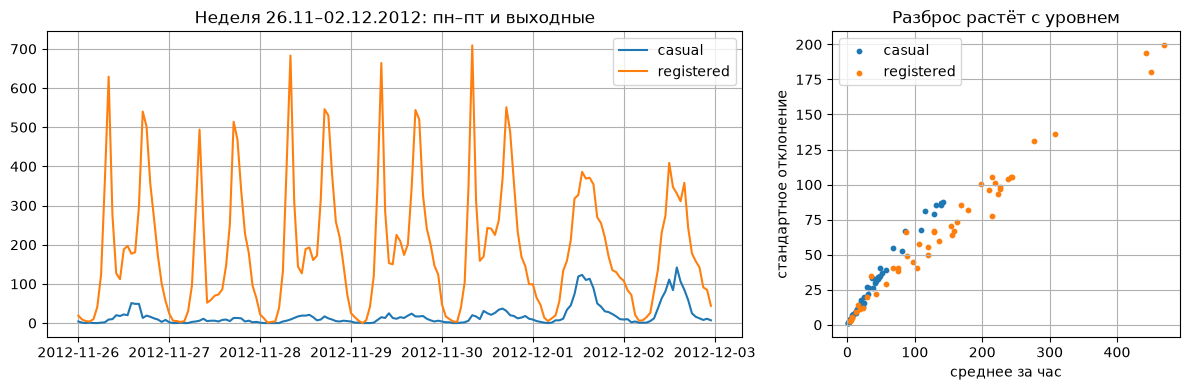

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
week = Y_df[(Y_df["ds"] >= "2012-11-26") & (Y_df["ds"] < "2012-12-03")]
for uid, s in week.groupby("unique_id"):
    axes[0].plot(s["ds"], s["y"], label=uid)
axes[0].set_title("Неделя 26.11–02.12.2012: пн–пт и выходные")
axes[0].legend()
stats = Y_df.groupby(["unique_id", Y_df["ds"].dt.hour, "workingday"])["y"].agg(["mean", "std"])
for uid, s in stats.groupby(level=0):
    axes[1].scatter(s["mean"], s["std"], s=10, label=uid)
axes[1].set_xlabel("среднее за час")
axes[1].set_ylabel("стандартное отклонение")
axes[1].set_title("Разброс растёт с уровнем")
axes[1].legend()
fig.tight_layout()

Каждая точка справа — один час суток (отдельно для будней и выходных). Разброс растёт вместе со средним:
ночью поездок мало и колеблются они мало, в час пик — много и колеблются сильно.
Нормальное распределение с одной и той же формой сюда подходит плохо: оно симметрично и ночью «уходит» в минус.

## 1. Напоминание: как оценивать распределение

- **Интервал уровня 80%** — между квантилями 0.1 и 0.9. **Покрытие** — доля фактов внутри интервала; для
  хорошей модели около 0.8. Ниже — модель слишком уверена, выше — интервалы зря широкие.
- **Ширина** интервала: при одинаковом покрытии чем уже, тем полезнее.
- **CRPS** — одна метрика на всё распределение (обобщение MAE на прогноз-распределение), меньше — лучше.
  `scaled_crps` из `utilsforecast` считает её по квантилям и нормирует на уровень ряда.

## 2. Два способа получить распределение из сети

| | `DistributionLoss` | `MQLoss` |
|---|---|---|
| что предсказывает сеть | параметры распределения (например, среднее и дисперсию) | сразу набор квантилей |
| обучение | максимизация правдоподобия | quantile (pinball) loss по всем квантилям |
| предположения | форма распределения задана: Normal, StudentT, Poisson, NegativeBinomial… | никаких |
| плюсы | любые квантили и сэмплы; знает про неотрицательность / целочисленность | гибкость формы |
| минусы | неверная форма → неверные интервалы | квантили могут уйти в минус и пересечься |

Для счётных данных с растущим разбросом естественный выбор — **отрицательное биномиальное** (NegBin):
неотрицательное, целочисленное, дисперсия больше среднего.

### Как сеть выдаёт параметры распределения (статья, разд. 3.1)

Из скрытого состояния $\mathbf{h}_t$ линейный слой выдаёт по одному числу на параметр. Чтобы параметр попал
в допустимую область, используется $\text{softplus}(x) = \log(1 + e^x) > 0$.

**Normal**, $\theta = (\mu, \sigma)$:
$$\mu = \mathbf{w}_\mu^\top \mathbf{h}_t + b_\mu, \qquad \sigma = \text{softplus}(\mathbf{w}_\sigma^\top \mathbf{h}_t + b_\sigma).$$

**NegBin**, $\theta = (\mu, \alpha)$ — среднее и параметр формы:
$$\ell_{NB}(z \mid \mu, \alpha) = \frac{\Gamma(z + 1/\alpha)}{\Gamma(z+1)\,\Gamma(1/\alpha)}
  \left(\frac{1}{1+\alpha\mu}\right)^{1/\alpha} \left(\frac{\alpha\mu}{1+\alpha\mu}\right)^{z},
  \qquad \mu = \text{softplus}(\cdot), \ \ \alpha = \text{softplus}(\cdot).$$

- $\operatorname{Var}[z] = \mu + \alpha\mu^2$: $\alpha$ задаёт, насколько дисперсия больше среднего.
  При $\alpha \to 0$ получается Пуассон ($\operatorname{Var} = \mu$).
- Разброс растёт вместе с уровнем — ровно то, что мы видели на графике «среднее — стандартное отклонение».
- Авторы пишут, что возможны и другие параметризации, но эта (через среднее) в их предварительных
  экспериментах особенно способствовала быстрой сходимости. В `torch.distributions` она переводится так: `total_count` $= 1/\alpha$,
  `probs` $= \alpha\mu / (1 + \alpha\mu)$ — так делает и neuralforecast.

Статья подчёркивает: подойдёт любое распределение, для которого можно дёшево сэмплировать и посчитать
логарифм правдоподобия и его градиент (бета — для долей, Бернулли — для бинарных данных, смеси).

**Пример.** Возьмём два часа ряда `registered` в будни: ночь и вечерний пик. По эмпирическим среднему и
дисперсии подберём $\alpha = (\operatorname{Var} - \mu)/\mu^2$ и сравним NegBin с Normal с теми же
средним и дисперсией.

,alpha,P(z<0) у Normal,5% Normal,5% NegBin,95% Normal,95% NegBin
"ночь, 04:00",0.204,0.064,-0.362,1.0,9.091,10.0
"вечерний пик, 17:00",0.178,0.009,142.214,196.0,797.881,838.0


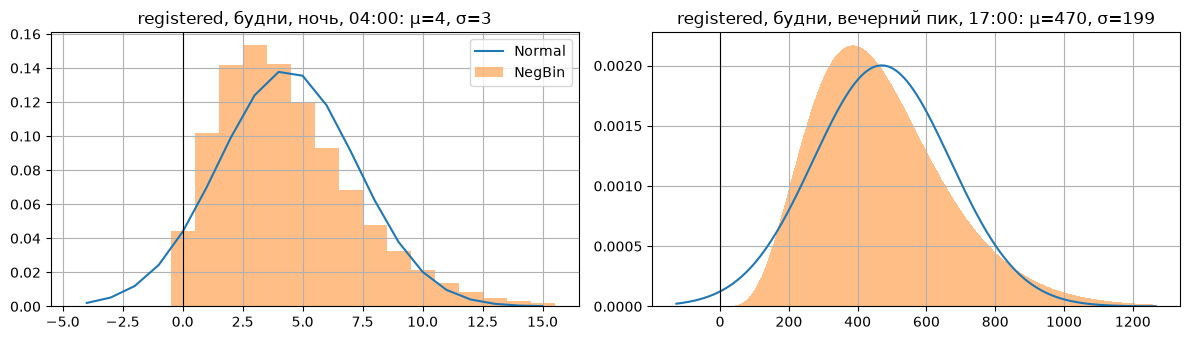

In [7]:
def negbin_dist(mu, alpha):
    """NegBin в параметризации статьи: среднее mu, Var = mu + alpha * mu^2."""
    return torch.distributions.NegativeBinomial(total_count=1 / alpha, probs=mu * alpha / (1 + mu * alpha))


fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
rows = {}
for ax, (title, hour) in zip(axes, [("ночь, 04:00", 4), ("вечерний пик, 17:00", 17)]):
    mu, sd = stats.loc[("registered", hour, 1.0)]
    alpha = (sd**2 - mu) / mu**2
    normal, nb = torch.distributions.Normal(mu, sd), negbin_dist(torch.tensor(mu), torch.tensor(alpha))
    z = torch.arange(int(mu - 3 * sd), int(mu + 4 * sd) + 1, dtype=torch.float32)
    nb_pmf = torch.where(z >= 0, nb.log_prob(z.clamp(min=0)).exp(), 0.0)
    nb_quantile = lambda q: z[torch.searchsorted(nb_pmf.cumsum(0), torch.tensor(q))].item()
    ax.bar(z, nb_pmf, width=1.0, alpha=0.5, color="tab:orange", label="NegBin")
    ax.plot(z, normal.log_prob(z).exp(), color="tab:blue", label="Normal")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"registered, будни, {title}: μ={mu:.0f}, σ={sd:.0f}")
    rows[title] = {
        "alpha": alpha,
        "P(z<0) у Normal": normal.cdf(torch.tensor(0.0)).item(),
        "5% Normal": normal.icdf(torch.tensor(0.05)).item(),
        "5% NegBin": nb_quantile(0.05),
        "95% Normal": normal.icdf(torch.tensor(0.95)).item(),
        "95% NegBin": nb_quantile(0.95),
    }
axes[0].legend()
fig.tight_layout()
pd.DataFrame(rows).T.round(3)

Среднее и дисперсия одинаковые, а форма разная:
- ночью Normal отдаёт заметную вероятность отрицательным значениям, а 5%-квантиль у неё меньше нуля;
- в пик NegBin скошено вправо: мода левее среднего, длинный правый хвост. Верхний квантиль у NegBin выше,
  чем у Normal, — для решения «сколько завезти велосипедов» это важно.

## 3. Постановка и базовая модель

Прогноз на сутки (`h=24`) по неделе истории (`input_size=168`), одна модель на оба ряда, 5 окон.
Точечная планка — `SeasonalNaive(168)`: те же часы неделю назад.

In [8]:
H = 24
L = 7 * 24
N_WINDOWS = 5
MAX_STEPS = 1000

sn = StatsForecast(models=[SeasonalNaive(168)], freq="h").cross_validation(
    df=Y_df[["unique_id", "ds", "y"]], h=H, n_windows=N_WINDOWS, step_size=H
)
cutoffs = sn["cutoff"].unique()
print("MAE SeasonalNaive(168):", round((sn["y"] - sn["SeasonalNaive"]).abs().mean(), 1))

MAE SeasonalNaive(168): 18.5


## 4. DeepAR

**Постановка (статья, разд. 3).** Для ряда $i$ со значениями $z_{i,t}$ и признаками $\mathbf{x}_{i,t}$,
известными на всём отрезке, нужно условное распределение будущего $z_{i,t_0:T}$ при известном прошлом
$z_{i,1:t_0-1}$. Отрезок $[1, t_0-1]$ называется **условным** (conditioning range), $[t_0, T]$ — **прогнозным**.

**Факторизация.** Совместное распределение будущего раскладывается в произведение одношаговых:
$$Q_\Theta(\mathbf{z}_{i,t_0:T} \mid \mathbf{z}_{i,1:t_0-1}, \mathbf{x}_{i,1:T})
  = \prod_{t=t_0}^{T} \ell\big(z_{i,t} \mid \theta(\mathbf{h}_{i,t})\big),
  \qquad \mathbf{h}_{i,t} = h\big(\mathbf{h}_{i,t-1},\, z_{i,t-1},\, \mathbf{x}_{i,t}\big).$$
- $h$ — многослойная LSTM. Она **авторегрессионная** (на вход подаётся прошлое значение $z_{t-1}$)
  и **рекуррентная** (на вход подаётся прошлое состояние $\mathbf{h}_{t-1}$).
- $\theta(\cdot)$ — голова, которая переводит состояние в параметры распределения (см. раздел 2).
- Энкодер и декодер — одна и та же сеть с общими весами: LSTM просто проходит условный отрезок, и её
  состояние в момент $t_0-1$ становится стартовым для прогноза.

**Обучение (разд. 3.2).** Максимизируем логарифм правдоподобия по всем рядам и шагам:
$$\mathcal{L} = \sum_{i=1}^{N} \sum_{t=t_0}^{T} \log \ell\big(z_{i,t} \mid \theta(\mathbf{h}_{i,t})\big).$$
Все $z_{t-1}$ на обучении известны (teacher forcing — на вход подаются настоящие значения), поэтому
$\mathbf{h}_t$ — детерминированная функция входа. В отличие от моделей пространства состояний с
латентными переменными (фильтр Калмана), никакого вывода скрытых состояний не нужно — обычный SGD.

**Прогноз — сэмплирование траекторий.** Прогноз строится шаг за шагом:
1. прогоняем LSTM по истории, получаем $\mathbf{h}_{t_0-1}$;
2. на шаге $t$ сэмплируем $\tilde z_t \sim \ell(\cdot \mid \theta(\mathbf{h}_t))$ и подаём $\tilde z_t$ на вход шага
   $t+1$ — так до конца горизонта; получается одна **траектория**;
3. повторяем много раз (в статье — 200 траекторий, разд. 6) и считаем квантили по траекториям: для каждого
   часа отдельно или для любой суммы, например, спроса за сутки.

Траектории сохраняют **связь между шагами**: если в 8 утра спрос оказался высоким, он продолжит влиять
на следующие часы. Квантиль суммы — не сумма квантилей, поэтому для сумм нужны именно траектории.

**Замечания из статьи.**
- *Расхождение обучения и прогноза* (разд. 3.2). На обучении на вход идут настоящие $z_{t-1}$, на прогнозе —
  сэмплы модели. В NLP это известная проблема (exposure bias); авторы пишут, что в прогнозировании
  вредного эффекта не заметили, а scheduled sampling точность не улучшил и замедлил сходимость.
- *Обучающие окна* (разд. 3.2). Из каждого ряда нарезается много окон одной длины с разными стартами.
  Абсолютное время модель видит только через признаки, а не через позицию в окне. Окна разрешено начинать
  **до** начала ряда, дополняя нулями, — так модель учится вести себя на «новых» рядах.

**Что делает neuralforecast иначе.**
- Loss считается только по последним `h` шагам окна, а статья включает в $\mathcal{L}$ и условный отрезок
  ($t_0 = 0$).
- На прогнозе на вход следующего шага подаётся **среднее** распределения, а не сэмпл. На каждом шаге из
  одношагового распределения берутся 100 независимых сэмплов (`trajectory_samples`), и квантили считаются по
  ним. Получаются квантили каждого часа по отдельности, а связанных траекторий нет: неопределённость
  прошлых шагов не переносится в следующие. Пример ниже показывает, к чему это приводит.

Рекуррентная сеть идёт по окну **последовательно**, шаг за шагом — поэтому она заметно медленнее MLP-моделей.
Облегчаем: `lstm_hidden_size=64` (по умолчанию 128) и `windows_batch_size=256` (по умолчанию 1024).
А вот окно урезать нельзя: с `input_size=48` DeepAR не успевает различить будни и выходные, и ошибка
вырастает вдвое.

Для сравнения, в статье на часовом датасете `electricity` (370 рядов) окна те же: история 168 часов, горизонт
24 часа; сеть — 3 слоя LSTM по 40 нейронов (табл. 3). У нас 2 слоя по 64 (по умолчанию в neuralforecast
`lstm_n_layers=2`).

### Пример: квантили из траекторий

Без обучения сети посмотрим, как из траекторий получаются квантили и что теряется без них. Вместо LSTM —
игрушечная авторегрессия: среднее часа $t$ — это средний профиль будней `registered`, сдвинутый вслед за
значением, поданным на вход с прошлого шага; шум — NegBin. Три варианта:
- **траектории (статья)** — на вход идёт сэмпл, траектории связные;
- **перемешанные** — те же сэмплы, но в каждом часе независимо перемешаны между траекториями. Квантили по
  часам не меняются, а связь между часами разрушена. Так авторы проверяли, важна ли эта связь (разд. 4.2, рис. 5);
- **на вход — среднее** — как в neuralforecast: неопределённость прошлых шагов не накапливается.

,"ширина 80% по часам, среднее",80%-интервал суммы за сутки
траектории (статья),155,2565–4917
перемешанные по часам,155,3174–4229
на вход — среднее (neuralforecast),99,3672–4321


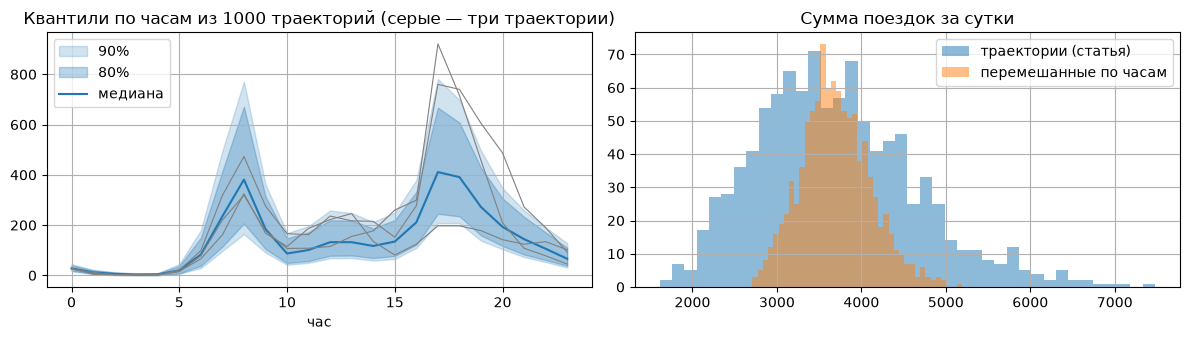

In [9]:
rng = np.random.default_rng(SEED)
profile = stats.loc["registered"].xs(1.0, level="workingday")["mean"].to_numpy()  # средние будни, 24 часа
N_PATHS, ALPHA, PHI = 1000, 0.05, 0.8


def simulate(feedback):
    """Игрушечная авторегрессия: среднее часа t сдвигается вслед за значением, поданным на вход с шага t-1."""
    paths = np.zeros((N_PATHS, 24))
    prev_ratio = np.ones(N_PATHS)
    for t in range(24):
        mu = profile[t] * prev_ratio**PHI
        paths[:, t] = rng.negative_binomial(1 / ALPHA, 1 / (1 + ALPHA * mu))  # numpy: n = 1/α, p = 1/(1+αμ)
        fed = paths[:, t] if feedback == "sample" else mu
        prev_ratio = (fed + 1) / (profile[t] + 1)
    return paths


paths = simulate("sample")
variants = {
    "траектории (статья)": paths,
    "перемешанные по часам": rng.permuted(paths, axis=0),
    "на вход — среднее (neuralforecast)": simulate("mean"),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
q = np.quantile(paths, [0.05, 0.1, 0.5, 0.9, 0.95], axis=0)
axes[0].fill_between(range(24), q[0], q[4], alpha=0.2, color="tab:blue", label="90%")
axes[0].fill_between(range(24), q[1], q[3], alpha=0.3, color="tab:blue", label="80%")
axes[0].plot(range(24), q[2], color="tab:blue", label="медиана")
axes[0].plot(range(24), paths[:3].T, color="gray", lw=0.8)
axes[0].set_title("Квантили по часам из 1000 траекторий (серые — три траектории)")
axes[0].set_xlabel("час")
axes[0].legend()
for name in ["траектории (статья)", "перемешанные по часам"]:
    axes[1].hist(variants[name].sum(axis=1), bins=40, alpha=0.5, label=name)
axes[1].set_title("Сумма поездок за сутки")
axes[1].legend()
fig.tight_layout()

widths = {}
for name, p in variants.items():
    lo, hi = np.quantile(p, [0.1, 0.9], axis=0)
    day_lo, day_hi = np.quantile(p.sum(axis=1), [0.1, 0.9])
    widths[name] = {"ширина 80% по часам, среднее": round((hi - lo).mean()), "80%-интервал суммы за сутки": f"{day_lo:.0f}–{day_hi:.0f}"}
pd.DataFrame(widths).T

- Квантили каждого часа считаются по столбцу матрицы траекторий, квантили суммы — по суммам строк.
- После перемешивания интервалы по часам те же, а интервал суммы за сутки заметно уже: высокий спрос в одном
  часе больше не тянет за собой соседние. В статье (рис. 5) перемешанный прогноз хуже откалиброван на
  отрезке из 9 шагов и даёт на 10% больший 0.9-risk (квантильный loss для квантиля 0.9).
- Если подавать на вход среднее, сужаются уже и **часовые** интервалы: модель не учитывает, что прошлые
  часы тоже могли пойти иначе. Это одна из возможных причин заниженного покрытия DeepAR в neuralforecast,
  которое мы увидим ниже.

### Нормализация и распределение должны быть согласованы

**Как это сделано в статье (разд. 3.3).** Масштабы рядов отличаются на порядки: у Amazon число товаров
в зависимости от скорости продаж подчиняется степенному закону (рис. 1). Отсюда две проблемы.
- *Масштаб входа и выхода.* Вход $z_{t-1}$ и выход $\mu$ растут вместе с рядом, а нелинейности сети работают
  в узком диапазоне. Поэтому вход делится на масштаб ряда
  $\nu_i = 1 + \frac{1}{t_0}\sum_{t=1}^{t_0} z_{i,t}$ (единица — чтобы не делить на ноль), а выход
  домножается обратно: $\mu = \nu_i \cdot \text{softplus}(o_\mu)$, $\alpha = \text{softplus}(o_\alpha)/\sqrt{\nu_i}$.
  Для счётных данных нельзя заранее нормировать сам ряд: после деления значения перестают быть целыми,
  и NegBin к ним неприменимо. Поэтому масштаб вносится внутрь параметров распределения.
- *Дисбаланс.* Рядов с большим масштабом мало, при равномерном выборе окон модель их почти не видит, а
  именно они часто важнее для бизнеса. Поэтому окно ряда выбирается с вероятностью, пропорциональной
  $\nu_i$ (weighted sampling).

В статье (табл. 1) это проверено напрямую: `rnn-negbin` — та же сеть с NegBin, но без масштабирования
и с равномерной выборкой окон. На данных Amazon со степенным законом масштабов она заметно хуже DeepAR
(средний относительный loss 1.17 против 0.77 на `ec-sub` и 0.93 против 0.85 на `ec`), а на `parts`, где
степенного закона нет, близка к нему (0.99 против 0.94).

У нас два ряда тоже разного масштаба: в среднем `registered` примерно в 4 раза больше `casual`.

**Как это сделано в neuralforecast.** Вместо деления на среднее — нормализация окна (`scaler_type`) со сдвигом
`loc` и масштабом `scale`; $\alpha$ делится на `scale + 1`, а не на $\sqrt{\nu}$; окна выбираются равномерно.
Сеть работает с нормированным окном, а параметры распределения возвращаются в исходную шкалу: среднее NegBin
= $\text{softplus}(\cdot) \cdot \text{scale} + \text{loc}$, где `loc` — сдвиг нормализации. Слагаемое с softplus
неотрицательно, значит **прогноз не может опуститься ниже `loc`**. В статье сдвига нет, и такой проблемы не возникает.
- `scaler_type="standard"`: `loc` — среднее окна. Ночью спрос ниже среднего за неделю, а модель так спрогнозировать
  не может.
- `scaler_type="minmax1"`: `loc` — минимум окна, у нас ≈ 0. Ограничение не мешает.

Проверим на N-HiTS с NegBin (он быстрее, а эффект тот же):

In [10]:
negbin = lambda: DistributionLoss("NegativeBinomial", level=LEVELS)
common = dict(
    h=H, input_size=L, max_steps=MAX_STEPS, learning_rate=1e-3, futr_exog_list=FUTR, random_seed=SEED, **TRAINER_KW
)
nf_scaler = NeuralForecast(
    models=[NHITS(alias=f"N-HiTS NegBin {s}", loss=negbin(), scaler_type=s, **common) for s in ["standard", "minmax1"]],
    freq="h",
)
cv_scaler = nf_scaler.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
prob_score(cv_scaler, [f"N-HiTS NegBin {s}" for s in ["standard", "minmax1"]])

,покрытие 80%,покрытие 90%,MAE медианы,CRPS,ширина 80%,нижняя граница < 0,квантили не по порядку
N-HiTS NegBin minmax1,0.862,0.942,21.150,0.124,83.103996,0.0,0.0
N-HiTS NegBin standard,0.804,0.912,59.552,0.260,190.404007,0.0,0.0


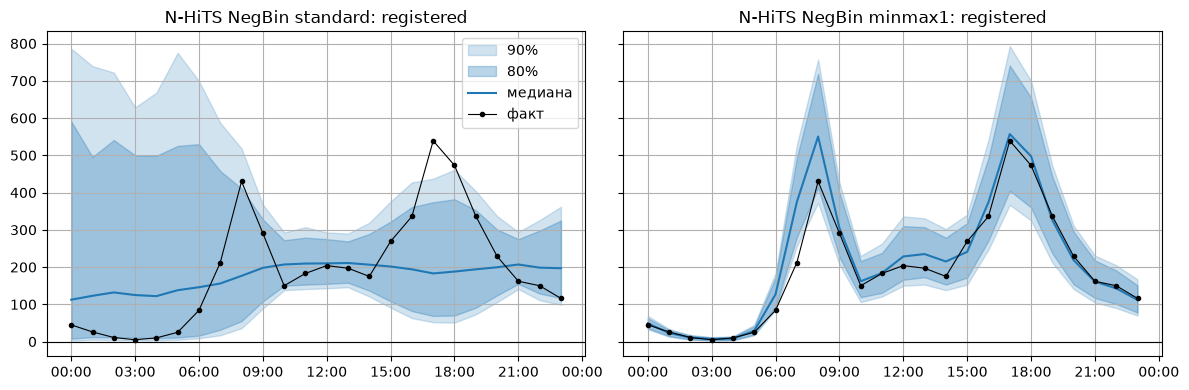

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, s in zip(axes, ["standard", "minmax1"]):
    plot_fan(cv_scaler, f"N-HiTS NegBin {s}", "registered", cutoffs[2], ax)
axes[0].legend()
fig.tight_layout()

Со `standard` ночной прогноз «застревает» на уровне среднего за неделю, интервалы раздуты. Дальше везде
используем `minmax1`.

### DeepAR: Normal или NegBin

Одна и та же сеть, разное распределение на выходе.

In [12]:
common = {**common, "scaler_type": "minmax1"}
deepar_kw = dict(lstm_hidden_size=64, windows_batch_size=256, **common)

cv_all = sn.copy()
train_time = {}
models = [
    DeepAR(alias="DeepAR Normal", loss=DistributionLoss("Normal", level=LEVELS), **deepar_kw),
    DeepAR(alias="DeepAR NegBin", loss=negbin(), **deepar_kw),
]
for m in models:
    nf = NeuralForecast(models=[m], freq="h")
    start = time.time()
    cv = nf.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
    train_time[m.alias] = time.time() - start
    cv_all = cv_all.merge(cv.drop(columns="y"), on=["unique_id", "ds", "cutoff"])
prob_score(cv_all, ["DeepAR Normal", "DeepAR NegBin"])

,покрытие 80%,покрытие 90%,MAE медианы,CRPS,ширина 80%,нижняя граница < 0,квантили не по порядку
DeepAR NegBin,0.617,0.721,21.767,0.164,42.887001,0.000,0.0
DeepAR Normal,0.896,0.938,40.633,0.311,219.024994,0.696,0.0


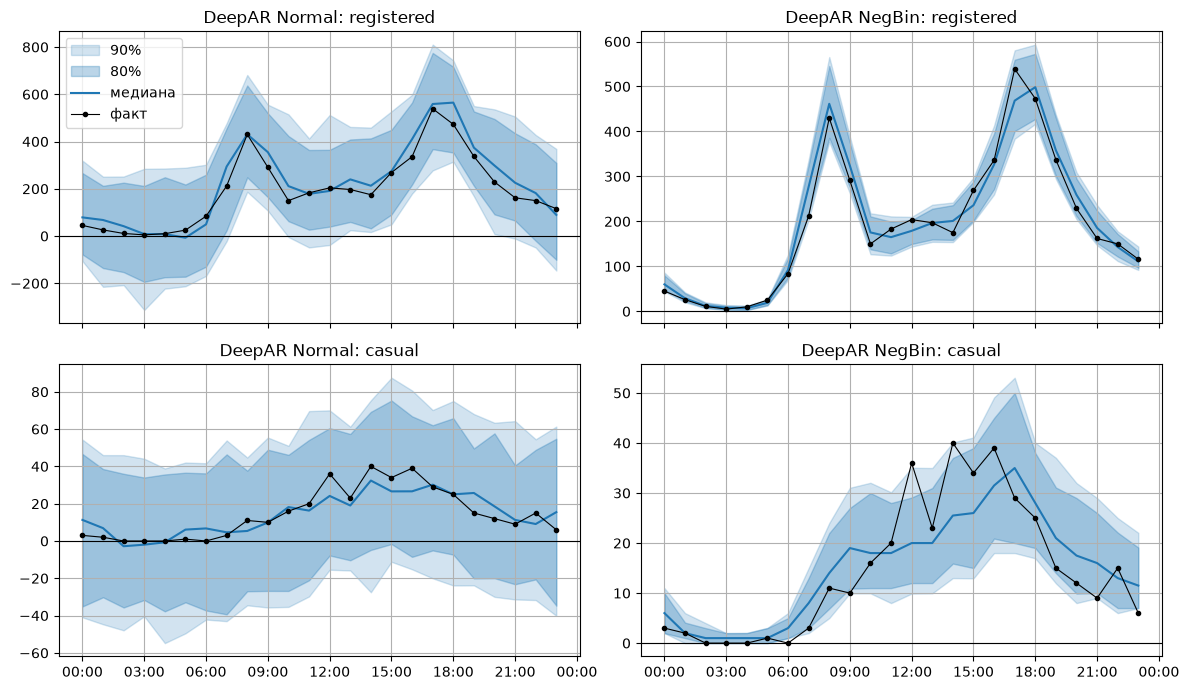

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for row, uid in enumerate(["registered", "casual"]):
    for col, m in enumerate(["DeepAR Normal", "DeepAR NegBin"]):
        plot_fan(cv_all, m, uid, cutoffs[2], axes[row, col])
axes[0, 0].legend()
fig.tight_layout()

- У **Normal** покрытие формально хорошее, но ценой огромной ширины интервалов, а ночью нижняя граница уходит
  в минус (минус велосипедов не бывает). Медиана заметно хуже.
- У **NegBin** интервалы неотрицательные, узкие ночью и широкие в часы пик, медиана точнее, CRPS вдвое лучше.
  Но покрытие ниже номинального: модель слишком уверена.

В статье то же самое (табл. 1): `rnn-gaussian` — та же архитектура с гауссовским правдоподобием
(и с упрощённым масштабированием, равномерной выборкой окон) — на счётных данных заметно хуже DeepAR с NegBin (средний относительный loss 1.19 против 0.94 на `parts`,
1.21 против 0.77 на `ec-sub`). Авторы делают вывод: для таких данных важно моделировать именно счётное
распределение.

Почему NegBin недопокрывает? Распределение на выходе описывает только шум данных (алеаторную
неопределённость), но не неуверенность самой модели. Вдобавок neuralforecast на прогнозе подаёт на вход
среднее, а не сэмпл, и неопределённость прошлых часов не накапливается (пример с траекториями выше).
Поэтому покрытие всегда надо **мерить**, а не верить уровню интервала (и при необходимости калибровать,
например, конформными методами — неделя 10). В статье калибровку тоже проверяют отдельно: на рис. 5 доля
фактов ниже $p$-квантиля сравнивается с $p$.

## 5. Loss ≠ архитектура

Вероятностность в DeepAR — заслуга не LSTM, а функции потерь. Возьмём N-HiTS из первого семинара и дадим
ему те же выходы:
- `MQLoss` — сеть сразу выдаёт квантили;
- `DistributionLoss("NegativeBinomial")` — ровно та же голова, что у DeepAR.

In [14]:
models = [
    NHITS(alias="N-HiTS MQLoss", loss=MQLoss(level=LEVELS), **common),
    NHITS(alias="N-HiTS NegBin", loss=negbin(), **common),
]
for m in models:
    nf = NeuralForecast(models=[m], freq="h")
    start = time.time()
    cv = nf.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
    train_time[m.alias] = time.time() - start
    cv_all = cv_all.merge(cv.drop(columns="y"), on=["unique_id", "ds", "cutoff"])

names = ["DeepAR Normal", "DeepAR NegBin", "N-HiTS MQLoss", "N-HiTS NegBin"]
summary = prob_score(cv_all, names)
summary["время, с"] = pd.Series(train_time).round(0)
summary

,покрытие 80%,покрытие 90%,MAE медианы,CRPS,ширина 80%,нижняя граница < 0,квантили не по порядку,"время, с"
N-HiTS NegBin,0.862,0.942,21.150,0.124,83.103996,0.000,0.000,33.0
N-HiTS MQLoss,0.771,0.900,22.305,0.134,65.017998,0.200,0.079,36.0
DeepAR NegBin,0.617,0.721,21.767,0.164,42.887001,0.000,0.000,143.0
DeepAR Normal,0.896,0.938,40.633,0.311,219.024994,0.696,0.000,232.0


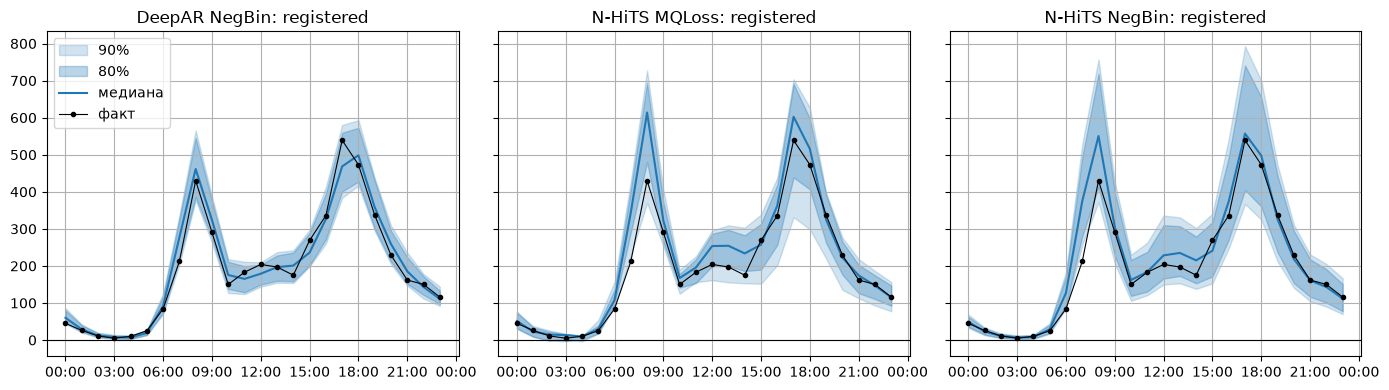

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, m in zip(axes, ["DeepAR NegBin", "N-HiTS MQLoss", "N-HiTS NegBin"]):
    plot_fan(cv_all, m, "registered", cutoffs[2], ax)
axes[0].legend()
fig.tight_layout()

- **N-HiTS + NegBin** — лучший по CRPS и покрытию и обучается в несколько раз быстрее DeepAR. Рекуррентная
  архитектура для вероятностного прогноза не обязательна: распределение даёт голова и функция потерь.
- **N-HiTS + MQLoss** точен по медиане, но его квантили ничего не знают о данных: нижние границы уходят в минус,
  а часть квантилей идёт не по порядку (90%-интервал уже 80%-го). Без предположений о форме — и без её защиты.
- **Выбор распределения важнее выбора архитектуры**: Normal vs NegBin в одной сети меняет картину сильнее,
  чем DeepAR vs N-HiTS с одним распределением.
- Статья сравнивает DeepAR только с классическими методами и вариантами той же RNN. Её ключевые приёмы —
  правдоподобие под данные и масштаб внутри параметров распределения — от LSTM не зависят и переносятся
  на любую архитектуру, что мы и сделали с N-HiTS.

Сравните с планкой: по точности медианы сети **не обходят** `SeasonalNaive(168)` (MAE 18.5) — на пяти
обычных сутках «как неделю назад» очень сильный прогноз. Ценность сетей здесь — в интервалах, которых у seasonal
naive нет. Точечная и вероятностная метрики ранжируют модели по-разному, поэтому смотреть надо на обе.

## 6. Для самостоятельного изучения

- **Калибровка.** `utilsforecast.losses.calibration` — доля фактов ниже каждого квантиля; для хорошей модели
  совпадает с самим квантилем.
- **Конформные интервалы** поверх точечной модели: `prediction_intervals=PredictionIntervals()` при обучении
  и `level=[80, 90]` при прогнозе — интервалы из ошибок на калибровочных окнах, без предположений
  о распределении (связь с неделей 10).
- **Смеси распределений:** `NBMM`, `GMM` из `neuralforecast.losses.pytorch` — для мультимодального спроса.
- **Poisson vs NegBin:** у Poisson дисперсия равна среднему. Хватит ли этого для `registered`?

Пример: конформные интервалы для точечного N-HiTS. Калибровочные окна берутся из обучающей части, поэтому
для каждого окна теста модель переобучается (`refit=True`) — это в 5 раз дольше.

In [16]:
from neuralforecast.utils import PredictionIntervals

nf_conf = NeuralForecast(models=[NHITS(alias="N-HiTS conformal", **common)], freq="h")
cv_conf = nf_conf.cross_validation(
    df=Y_df,
    n_windows=N_WINDOWS,
    step_size=H,
    refit=True,
    prediction_intervals=PredictionIntervals(n_windows=5),
    level=LEVELS,
)
cv_conf["N-HiTS conformal-median"] = cv_conf["N-HiTS conformal"]
prob_score(cv_conf, ["N-HiTS conformal"])

,покрытие 80%,покрытие 90%,MAE медианы,CRPS,ширина 80%,нижняя граница < 0,квантили не по порядку
N-HiTS conformal,0.629,0.708,30.294,0.237,66.991,0.338,0.0


Конформные интервалы здесь получились хуже NegBin: покрытие ниже номинального, треть нижних границ меньше нуля.
Интервал строится из ошибок точечной модели на 5 калибровочных сутках — одинаковой ширины для ночи и часа пик.
Гарантия покрытия конформных методов — в среднем и при похожих калибровочных и тестовых данных; на счётных
данных с разбросом, растущим с уровнем, правильное распределение работает лучше. Попробуйте больше
калибровочных окон и `PredictionIntervals(method="conformal_error")`.

## 7. Итоги недели: что настроить под задачу

| задача | что делать |
|---|---|
| быстрый сильный бейзлайн | DLinear; обязательно сравнить с seasonal naive |
| нужна интерпретация прогноза | N-BEATS / NBEATSx интерпретируемый: тренд + сезонность + экзогенные |
| длинный горизонт | N-HiTS: та же точность дешевле |
| известно будущее (календарь, прогнозы) | `futr_exog_list` + `futr_df` при прогнозе; только настоящие прогнозы, без утечки |
| нужен диапазон, а не точка | `DistributionLoss` (форма под данные) или `MQLoss`; покрытие — мерить |
| счётные данные | NegBin / Poisson и нормализация со сдвигом ≈ 0 |
| нужен интервал для суммы за период | квантили по связным траекториям, а не сумма квантилей по шагам |
| сравнение моделей | несколько окон, несколько сидов, честная планка |